# From Tables to Networks: DQN, and the Cross-Entropy Method

**ESE 561, Theory of Artificial Intelligence. Lecture notebook.**

So far every RL method stored **one number per state** (or per state–action pair). Today we leave tables behind, in two very different ways:

| part | idea | what is learned | what it needs |
|---|---|---|---|
| A–C | **DQN**: Q-learning with a neural network $Q_\theta(s,a)$, made stable by **experience replay** and a **target network** | values | the Bellman equation, every transition |
| D | DQN on **Atari**: pixels, frame stacks, and what a fixed window of frames cannot remember | values | a Markov state |
| E | **Cross-entropy method**: search directly over policies, keep the best, repeat | a policy | only the return of each episode |

In [1]:
# !pip install "gymnasium[classic-control]" torch     # uncomment if needed
import warnings
warnings.filterwarnings("ignore", message="pkg_resources is deprecated")
import copy, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
import torch
import torch.nn as nn
import torch.nn.functional as F
import gymnasium as gym

env = gym.make("CartPole-v1", render_mode="rgb_array")
n_obs, n_act = env.observation_space.shape[0], env.action_space.n
print(f'state dimension {n_obs}, {n_act} actions')

state dimension 4, 2 actions


initial state: [ 0.014 -0.023 -0.046 -0.048]


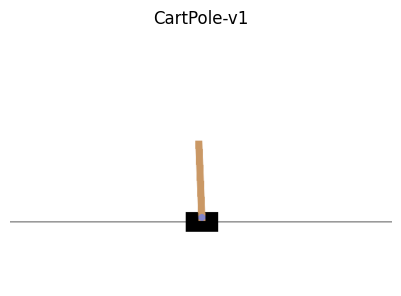

random policy: mean return 22.4, max 60 (the goal is 500)


In [2]:
s, _ = env.reset(seed=0)
print('initial state:', np.round(s, 3))
plt.figure(figsize=(5, 3.3)); plt.imshow(env.render()); plt.axis('off'); plt.title('CartPole-v1'); plt.show()

rng = np.random.default_rng(0)
lengths = []
for _ in range(100):
    s, _ = env.reset(seed=int(rng.integers(1 << 31))); done, G = False, 0
    while not done:
        s, r, term, trunc, _ = env.step(int(rng.integers(n_act))); done = term or trunc; G += r
    lengths.append(G)
print(f'random policy: mean return {np.mean(lengths):.1f}, max {max(lengths):.0f} (the goal is 500)')

## Part A. Function approximation

### A.1 Why tables stop working

* **Continuous states.** CartPole's state $(x,\dot x,\vartheta,\dot\vartheta)\in\mathbb R^4$ is almost never visited twice. A table learns nothing that transfers from one state to a nearby one.
* **Huge discrete states.** An Atari input is four $84\times84$ grayscale images: $256^{28224}$ possible inputs.

We need a function $Q_\theta(s,a)$ with far fewer parameters than states, which **generalizes**: similar inputs get similar values, so one update teaches the agent about many states at once.

* **Linear:** $Q_\theta(s,a)=\theta^\top\phi(s,a)$ with hand-made features $\phi$.
* **Neural network:** $Q_\theta(s,\cdot)\in\mathbb R^{|\mathcal A|}$, **one output per action**. One forward pass gives all action values, which is what $\max_{a'}$ and ε-greedy need.

In [3]:
def make_qnet():
    return nn.Sequential(nn.Linear(n_obs, 64), nn.ReLU(),
                         nn.Linear(64, 64), nn.ReLU(),
                         nn.Linear(64, n_act))

torch.manual_seed(0)
q = make_qnet()
s, _ = env.reset(seed=0)
print('Q(s, .) =', q(torch.as_tensor(s)).detach().numpy())
print('number of parameters:', sum(p.numel() for p in q.parameters()))

Q(s, .) = [0.13680057 0.00196303]
number of parameters: 4610


### A.2 From the tabular update to a gradient step

If we knew the true values, we would fit them by least squares, $\min_\theta\frac12\,\mathbb E\bigl[(Q^*(s,a)-Q_\theta(s,a))^2\bigr]$, with stochastic gradient steps
$$
\theta\leftarrow\theta+\alpha\,\bigl(Q^*(s,a)-Q_\theta(s,a)\bigr)\,\nabla_\theta Q_\theta(s,a).
$$
$Q^*$ is unknown, so, exactly as in tabular Q-learning, we replace it by the **sampled target** computed with the **current (old) values**:
$$
\boxed{\;\theta\leftarrow\theta+\alpha\,\bigl(Y-Q_\theta(s,a)\bigr)\,\nabla_\theta Q_\theta(s,a),\qquad Y=r+\gamma\,(1-d)\max_{a'}Q_\theta(s',a')\;}
$$
with $d=1$ if $s'$ is terminal.

* **Semi-gradient.** $Y$ depends on $\theta$ too, but we do not differentiate through it: it is held fixed, like the "old values" in the tabular target. In code: compute $Y$ under `torch.no_grad()`. This is not the gradient of any fixed loss.
* **The table is a special case.** With one-hot features $\phi(s,a)=e_{(s,a)}$, $\nabla_\theta Q_\theta(s,a)=e_{(s,a)}$ and the step changes one coordinate by $\alpha(Y-Q)$: tabular Q-learning. Let us check it on the toy MDP from the previous lectures.

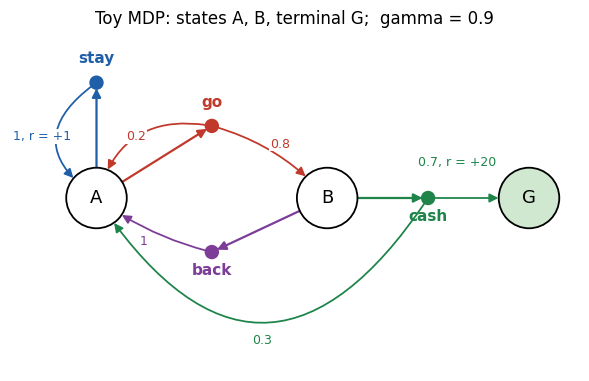

Q* = {'A,stay': 15.5, 'A,go': 16.11, 'B,cash': 18.35, 'B,back': 14.5}


In [4]:
# ---- the toy MDP from the previous lectures: states A, B, terminal G
from matplotlib.patches import FancyArrowPatch, Circle
TERMINAL = {'G'}
ACTIONS = {'A': ['stay', 'go'], 'B': ['cash', 'back'], 'G': []}
P = {('A', 'stay'): [('A', 1.0, 1.0)],
     ('A', 'go'):   [('B', 0.8, 0.0), ('A', 0.2, 0.0)],
     ('B', 'cash'): [('G', 0.7, 20.0), ('A', 0.3, 0.0)],
     ('B', 'back'): [('A', 1.0, 0.0)]}
PAIRS = list(P)                      # the 4 state-action pairs, in this order
gamma_toy = 0.9

def toy_step(s, a, rng):
    out = P[(s, a)]
    k = rng.choice(len(out), p=[p for _, p, _ in out])
    return out[k][0], out[k][2]

# exact Q* by value iteration with the model (for comparison)
Q_star = {sa: 0.0 for sa in PAIRS}
for _ in range(500):
    Q_star = {(s, a): sum(p * (r + gamma_toy * (0 if s2 in TERMINAL else max(Q_star[(s2, b)] for b in ACTIONS[s2])))
                          for s2, p, r in P[(s, a)]) for (s, a) in PAIRS}

COL = {'stay': '#1f5fa8', 'go': '#c0392b', 'cash': '#1e8449', 'back': '#7d3c98'}

def _arrow(ax, p, q, color, lw=1.6, rad=0.0, alpha=1.0, z=1, shrinkA=17, shrinkB=17):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle='-|>', mutation_scale=13, color=color, lw=lw,
                                 connectionstyle=f'arc3,rad={rad}', shrinkA=shrinkA, shrinkB=shrinkB,
                                 alpha=alpha, zorder=z))

def _node(ax, xy, text, fc='white', r=0.28, fs=11, ec='k', lw=1.3):
    ax.add_patch(Circle(xy, r, fc=fc, ec=ec, lw=lw, zorder=3))
    ax.text(*xy, text, ha='center', va='center', fontsize=fs, zorder=4)

def _label(ax, xy, text, color, fs=9):
    ax.text(*xy, text, color=color, ha='center', va='center', fontsize=fs, zorder=6,
            bbox=dict(fc='white', ec='none', pad=0.6))

def draw_mdp(V=None, policy=None, ax=None, title='The MDP as a graph'):
    """State graph with action nodes. V: optional values shown in the states;
    policy: optional dict state -> action, drawn in bold (others faded)."""
    ax = ax or plt.gca()
    pos = {'A': (0, 0), 'B': (3.2, 0), 'G': (6.0, 0)}
    act_pos = {('A', 'stay'): (0, 1.6), ('A', 'go'): (1.6, 1.0), ('B', 'cash'): (4.6, 0.0), ('B', 'back'): (1.6, -0.75)}
    rads = {('A', 'stay', 'A'): 0.7, ('A', 'go', 'A'): 0.45, ('A', 'go', 'B'): -0.15,
            ('B', 'cash', 'A'): -0.75, ('B', 'back', 'A'): -0.1}
    lab_pos = {('A', 'stay', 'A'): (-0.75, 0.85), ('A', 'go', 'A'): (0.55, 0.85), ('A', 'go', 'B'): (2.55, 0.75),
               ('B', 'cash', 'G'): (5.0, 0.5), ('B', 'cash', 'A'): (2.3, -1.98), ('B', 'back', 'A'): (0.65, -0.6)}
    for s, xy in pos.items():
        txt = s if V is None else f'{s}\n{V[s]:.2f}'
        _node(ax, xy, txt, fc='#cfe8cf' if s in TERMINAL else 'white', r=0.42, fs=13 if V is None else 10)
    for (s, a), xy in act_pos.items():
        on = policy is None or policy.get(s) == a
        alpha, lw = (1.0, 1.6) if on else (0.25, 1.0)
        ax.add_patch(Circle(xy, 0.09, fc=COL[a], ec=COL[a], zorder=4, alpha=alpha))
        dy = -0.32 if a in ('back', 'cash') else 0.27
        ax.text(xy[0], xy[1] + dy, a, color=COL[a], ha='center', fontsize=11, weight='bold', alpha=max(alpha, .4))
        _arrow(ax, pos[s], xy, COL[a], lw=lw * (1.6 if on and policy else 1), shrinkA=22, shrinkB=4, alpha=alpha)
        for s2, p, r in P[(s, a)]:
            _arrow(ax, xy, pos[s2], COL[a], lw=lw * 0.8, rad=rads.get((s, a, s2), 0.0), shrinkA=4, shrinkB=22, alpha=alpha)
            if on:
                _label(ax, lab_pos[(s, a, s2)], f'{p:g}' + (f', r = {r:+g}' if r else ''), COL[a])
    ax.set_xlim(-1.2, 6.7); ax.set_ylim(-2.4, 2.3); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title, fontsize=12)
    return ax


fig, ax = plt.subplots(figsize=(7.5, 4.4))
draw_mdp(ax=ax, title='Toy MDP: states A, B, terminal G;  gamma = 0.9')
plt.show()
print('Q* =', {f'{s},{a}': round(v, 2) for (s, a), v in Q_star.items()})

**Q-learning on this MDP as a one-layer network.** Each pair $(s,a)$ is fed in as a one-hot vector $\phi(s,a)\in\mathbb R^4$, and the "network" is `nn.Linear(4, 1, bias=False)`, so $Q_\theta(s,a)=\theta^\top\phi(s,a)$: each weight **is** one table entry. One training step:
1. sample a pair $(s,a)$ (here uniformly, as a replay buffer would) and let the environment sample $s',r$;
2. the target $Y=r+\gamma\max_b Q_\theta(s',b)$, computed under `torch.no_grad()` (old values);
3. the loss $\frac12(Y-Q_\theta(s,a))^2$, `backward()`, and one SGD step with learning rate $\alpha$.

The cell prints every intermediate value: the one-hot input, the weights before, the target, the loss, the **gradient** (look where it is nonzero), the weights after, and the tabular rule computed by hand.

In [8]:
def phi_onehot(s, a):
    x = torch.zeros(len(PAIRS)); x[PAIRS.index((s, a))] = 1.0
    return x

def show(w):
    """Print 4 values labelled by the pairs, or any other weight vector as theta_1..theta_k."""
    w = list(w)
    if len(w) == len(PAIRS):
        return '  '.join(f'{s},{a}={v:6.2f}' for (s, a), v in zip(PAIRS, w))
    return '  '.join(f'theta_{i + 1}={v:6.2f}' for i, v in enumerate(w))

def q_values(net, phi, s):
    with torch.no_grad():
        return {b: float(net(phi(s, b))) for b in ACTIONS[s]}

def q_step(net, opt, phi, s, a, rng, verbose=True, lr=None):
    """One Q-learning step on the pair (s, a). With opt=None, a plain SGD step with learning rate lr."""
    s2, r = toy_step(s, a, rng)
    with torch.no_grad():                                     # target from the OLD parameters
        nxt = 0.0 if s2 in TERMINAL else max(q_values(net, phi, s2).values())
    Y = r + gamma_toy * nxt
    x = phi(s, a)
    q_sa = net(x).squeeze()
    loss = 0.5 * (Y - q_sa) ** 2
    net.weight.grad = None                                    # clear the old gradient
    loss.backward()
    w_before = net.weight.detach().numpy().ravel().copy()
    grad = np.asarray(net.weight.grad).ravel().copy()
    if opt is not None:
        opt.step()
    else:
        with torch.no_grad():
            net.weight -= lr * net.weight.grad
    if verbose:
        print(f'sampled (s,a)=({s},{a})  ->  env: s\'={s2}, r={r:g}')
        print(f'   input phi(s,a)    = {x.numpy()}')
        print(f'   weights before    = [{show(w_before)}]')
        print(f'   target Y = r + gamma*max_b Q(s\',b) = {r:g} + {gamma_toy}*{nxt:.3f} = {Y:.3f}')
        print(f'   Q(s,a) = {float(q_sa):.3f},  loss = 0.5*(Y-Q)^2 = {float(loss):.3f}')
        print(f'   gradient dL/dw    = {np.round(grad, 3)}      (= -(Y-Q) * phi)')
        print(f'   weights after     = [{show(net.weight.detach().numpy().ravel())}]')
    return float(q_sa), Y

torch.manual_seed(0)
alpha = 0.5
net = nn.Linear(len(PAIRS), 1, bias=False)
with torch.no_grad():
    net.weight.zero_()                                       # start from Q = 0, like the table
opt = torch.optim.SGD(net.parameters(), lr=alpha)
toy_rng = np.random.default_rng(25)
for t in range(6):
    s, a = PAIRS[toy_rng.integers(len(PAIRS))]
    print(f'--- step {t + 1}')
    q_old, Y = q_step(net, opt, phi_onehot, s, a, toy_rng)
    print(f'   tabular rule: Q <- Q + alpha*(Y - Q) = {q_old:.3f} + {alpha}*({Y:.3f} - {q_old:.3f}) = {q_old + alpha * (Y - q_old):.3f}')

--- step 1
sampled (s,a)=(B,cash)  ->  env: s'=G, r=20
   input phi(s,a)    = [0. 0. 1. 0.]
   weights before    = [A,stay=  0.00  A,go=  0.00  B,cash=  0.00  B,back=  0.00]
   target Y = r + gamma*max_b Q(s',b) = 20 + 0.9*0.000 = 20.000
   Q(s,a) = 0.000,  loss = 0.5*(Y-Q)^2 = 200.000
   gradient dL/dw    = [  0.   0. -20.   0.]      (= -(Y-Q) * phi)
   weights after     = [A,stay=  0.00  A,go=  0.00  B,cash= 10.00  B,back=  0.00]
   tabular rule: Q <- Q + alpha*(Y - Q) = 0.000 + 0.5*(20.000 - 0.000) = 10.000
--- step 2
sampled (s,a)=(A,stay)  ->  env: s'=A, r=1
   input phi(s,a)    = [1. 0. 0. 0.]
   weights before    = [A,stay=  0.00  A,go=  0.00  B,cash= 10.00  B,back=  0.00]
   target Y = r + gamma*max_b Q(s',b) = 1 + 0.9*0.000 = 1.000
   Q(s,a) = 0.000,  loss = 0.5*(Y-Q)^2 = 0.500
   gradient dL/dw    = [-1.  0.  0.  0.]      (= -(Y-Q) * phi)
   weights after     = [A,stay=  0.50  A,go=  0.00  B,cash= 10.00  B,back=  0.00]
   tabular rule: Q <- Q + alpha*(Y - Q) = 0.000 + 0.5*(1.

In every step the gradient is nonzero in **one** coordinate only, and the new weight equals the tabular update. Now run many steps with a decreasing learning rate, $\alpha_n=n^{-0.7}$ per pair (Robbins–Monro), and compare with $Q^*$:

In [9]:
def train_toy(phi, n_feat, n_steps=20000, seed=0):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    net = nn.Linear(n_feat, 1, bias=False)
    with torch.no_grad(): net.weight.zero_()
    count = {sa: 0 for sa in PAIRS}
    for t in range(n_steps):
        s, a = PAIRS[rng.integers(len(PAIRS))]              # uniform over pairs, like a replay buffer
        count[(s, a)] += 1
        q_step(net, None, phi, s, a, rng, verbose=False, lr=count[(s, a)] ** -0.7)
    return net

net_tab = train_toy(phi_onehot, 4)
with torch.no_grad():
    learned = {sa: float(net_tab(phi_onehot(*sa))) for sa in PAIRS}
print('learned:', show(learned.values()))
print('Q*     :', show(Q_star.values()))

learned: A,stay= 15.58  A,go= 16.15  B,cash= 18.42  B,back= 14.57
Q*     : A,stay= 15.50  A,go= 16.11  B,cash= 18.35  B,back= 14.50


**Now a real function approximator: shared features.** Replace the one-hot input by 3 features shared between pairs,
$$
\phi(s,a)=\bigl(\mathbf 1\{s=A\},\ \mathbf 1\{s=B\},\ \mathbf 1\{a\in\{\text{go},\text{cash}\}\}\bigr),
$$
a value per state plus one common bonus for "moving forward". Then $Q(A,\text{go})=\theta_1+\theta_3$ and $Q(B,\text{cash})=\theta_2+\theta_3$ share $\theta_3$. One update on $(B,\text{cash})$ **also changes** $Q(A,\text{go})$:

In [10]:
def phi_shared(s, a):
    return torch.tensor([float(s == 'A'), float(s == 'B'), float(a in ('go', 'cash'))])

torch.manual_seed(0)
net_sh = nn.Linear(3, 1, bias=False)
with torch.no_grad(): net_sh.weight.zero_()
opt_sh = torch.optim.SGD(net_sh.parameters(), lr=0.5)

def table(net, phi):
    with torch.no_grad():
        return [float(net(phi(*sa))) for sa in PAIRS]

print('Q before:', show(table(net_sh, phi_shared)))
q_step(net_sh, opt_sh, phi_shared, 'B', 'cash', np.random.default_rng(0))
print('Q after: ', show(table(net_sh, phi_shared)))
print('one update on (B,cash) also moved Q(A,go) (shared theta_3) and Q(B,back) (shared theta_2): generalization')

net_sh = train_toy(phi_shared, 3)
print('\nafter 20000 steps with shared features:')
print('learned:', show(table(net_sh, phi_shared)))
print('Q*     :', show(Q_star.values()))
greedy = {s: max(ACTIONS[s], key=lambda b: float(net_sh(phi_shared(s, b)).detach())) for s in ('A', 'B')}
print('greedy policy from the approximate Q:', greedy)

Q before: A,stay=  0.00  A,go=  0.00  B,cash=  0.00  B,back=  0.00
sampled (s,a)=(B,cash)  ->  env: s'=G, r=20
   input phi(s,a)    = [0. 1. 1.]
   weights before    = [theta_1=  0.00  theta_2=  0.00  theta_3=  0.00]
   target Y = r + gamma*max_b Q(s',b) = 20 + 0.9*0.000 = 20.000
   Q(s,a) = 0.000,  loss = 0.5*(Y-Q)^2 = 200.000
   gradient dL/dw    = [  0. -20. -20.]      (= -(Y-Q) * phi)
   weights after     = [theta_1=  0.00  theta_2= 10.00  theta_3= 10.00]
Q after:  A,stay=  0.00  A,go= 10.00  B,cash= 20.00  B,back= 10.00
one update on (B,cash) also moved Q(A,go) (shared theta_3) and Q(B,back) (shared theta_2): generalization

after 20000 steps with shared features:
learned: A,stay= 14.87  A,go= 16.50  B,cash= 17.53  B,back= 15.90
Q*     : A,stay= 15.50  A,go= 16.11  B,cash= 18.35  B,back= 14.50
greedy policy from the approximate Q: {'A': 'go', 'B': 'cash'}


With 3 parameters for 4 values the network **cannot** represent $Q^*$: the forward bonus would have to be $16.11-15.50=0.61$ in $A$ and $18.35-14.50=3.85$ in $B$ at the same time. Q-learning settles on a compromise, wrong in every entry, yet the greedy policy can still be right. This is the price and the point of function approximation: fewer parameters than states, values that are only approximate, and updates that spread to similar inputs.

### A.3 Why it can diverge

For tables, convergence came from the $\gamma$-contraction of the Bellman operator plus Robbins–Monro. With function approximation, each update is a step towards $TQ_\theta$ **followed by a projection** onto the functions the model can represent, and the composition need not be a contraction.

**The smallest example** (Sutton and Barto, Section 11.2). Two states with one feature each, $x_1=1$ and $x_2=2$, and a linear value $V_\theta=\theta x$, so $V(s_1)=\theta$, $V(s_2)=2\theta$. From $s_1$ the agent moves to $s_2$ with reward $0$; from $s_2$ to a terminal state with reward $0$. All true values are $0$, and $\theta=0$ represents them **exactly**. A TD update on the transition $s_1\to s_2$:
$$
\theta\leftarrow\theta+\alpha\,(0+\gamma\cdot2\theta-\theta)\cdot1=\bigl(1+\alpha(2\gamma-1)\bigr)\,\theta .
$$
For $\gamma>\tfrac12$ the factor is larger than 1. If the data contain this transition more often than the one from $s_2$ (an off-policy distribution), $\theta$ grows without bound.

In [11]:
def two_state_td(updates_from_s2, gamma=0.9, alpha=0.1, n_rounds=60, theta=1.0):
    """Each round: one TD update on s1 -> s2, and `updates_from_s2` updates on s2 -> terminal."""
    out = [theta]
    for _ in range(n_rounds):
        theta += alpha * (0 + gamma * 2 * theta - theta) * 1          # s1 -> s2, feature x1 = 1
        for _ in range(updates_from_s2):
            theta += alpha * (0 - 2 * theta) * 2                      # s2 -> terminal, feature x2 = 2
        out.append(theta)
    return out

for k, label in [(0, 'only s1 -> s2 is updated (off-policy data)'), (1, 's1 -> s2 and s2 -> end equally often (on-policy)')]:
    th = two_state_td(k)
    print(f'{label:52s} theta after 0, 20, 40, 60 rounds: ' + ', '.join(f'{th[i]:.3g}' for i in (0, 20, 40, 60)))

only s1 -> s2 is updated (off-policy data)           theta after 0, 20, 40, 60 rounds: 1, 4.66, 21.7, 101
s1 -> s2 and s2 -> end equally often (on-policy)     theta after 0, 20, 40, 60 rounds: 1, 0.00017, 2.9e-08, 4.95e-12


**The deadly triad** (Sutton and Barto, Section 11.3). Divergence is possible when three ingredients meet:
1. **function approximation** (generalization between states),
2. **bootstrapping** (targets built from current estimates),
3. **off-policy** learning (the data distribution differs from that of the policy being evaluated).

Q-learning with a network has all three. Known results: on-policy TD with linear features converges (Tsitsiklis and Van Roy, 1997); off-policy linear TD can diverge (Baird, 1995); for neural networks there are no general guarantees.

**The mechanism in CartPole.** Consecutive states differ very little, $s'\approx s$, so the network gives them similar values. Raising $Q_\theta(s,a)$ also raises $\max_{a'}Q_\theta(s',a')$, which is the target we just used: **the target runs away from the estimate that chases it.** With $\gamma=0.99$ the true values are at most $1/(1-\gamma)=100$.

### A.4 One training function for all variants

`train(replay=..., target=...)` below is used for all experiments. Read it now; Parts B and C explain the two switches. We record the **Q-scale**, the mean of $\max_aQ_\theta(s,a)$ over 500 fixed states: it should stay below 100.

In [12]:
class ReplayBuffer:
    """The last `capacity` transitions (s, a, r, s', terminated), sampled uniformly at random."""
    def __init__(self, capacity, rng):
        self.S = np.zeros((capacity, n_obs), np.float32); self.S2 = np.zeros((capacity, n_obs), np.float32)
        self.A = np.zeros(capacity, np.int64); self.R = np.zeros(capacity, np.float32); self.D = np.zeros(capacity, np.float32)
        self.capacity, self.n, self.i, self.rng = capacity, 0, 0, rng
    def push(self, s, a, r, s2, d):
        self.S[self.i], self.A[self.i], self.R[self.i], self.S2[self.i], self.D[self.i] = s, a, r, s2, d
        self.i = (self.i + 1) % self.capacity; self.n = min(self.n + 1, self.capacity)
    def sample(self, batch):
        idx = self.rng.integers(self.n, size=batch)
        return tuple(torch.as_tensor(x[idx]) for x in (self.S, self.A, self.R, self.S2, self.D))
    def __len__(self):
        return self.n

def act(q, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(n_act))
    with torch.no_grad():
        return int(q(torch.as_tensor(s)).argmax())

def greedy_return(q, n=5, seed=123):
    """Average return of the greedy policy (eps = 0) over n episodes."""
    rng = np.random.default_rng(seed); total = 0.0
    for _ in range(n):
        s, _ = env.reset(seed=int(rng.integers(1 << 31))); done = False
        while not done:
            s, r, term, trunc, _ = env.step(act(q, s, 0.0, rng)); done = term or trunc; total += r
    return total / n

# a fixed set of states (from a random policy) on which we monitor the scale of the Q-values
_rng = np.random.default_rng(42); PROBE = []
while len(PROBE) < 500:
    s, _ = env.reset(seed=int(_rng.integers(1 << 31))); done = False
    while not done and len(PROBE) < 500:
        PROBE.append(s); s, r, term, trunc, _ = env.step(int(_rng.integers(n_act))); done = term or trunc
PROBE = torch.as_tensor(np.array(PROBE))

def train(replay=True, target=True, n_episodes=300, gamma=0.99, lr=1e-3, batch=64, capacity=50_000,
          target_every=200, eps_steps=3000, eps_end=0.05, double=False, timeout_is_terminal=False,
          eval_every=25, seed=0, verbose=True):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    q = make_qnet(); q_target = make_qnet(); q_target.load_state_dict(q.state_dict())
    opt = torch.optim.Adam(q.parameters(), lr=lr)
    buf = ReplayBuffer(capacity, rng)
    log = dict(returns=[], q_scale=[], evals=[], best=None, best_return=-1.0)
    step, t0 = 0, time.time()
    for ep in range(1, n_episodes + 1):
        s, _ = env.reset(seed=int(rng.integers(1 << 31))); done, G = False, 0.0
        while not done:
            eps = max(eps_end, 1 - (1 - eps_end) * step / eps_steps)
            a = act(q, s, eps, rng)
            s2, r, term, trunc, _ = env.step(a); done = term or trunc; G += r; step += 1
            d = float(term or trunc) if timeout_is_terminal else float(term)
            if replay:
                buf.push(s, a, r, s2, d)
                if len(buf) < batch:
                    s = s2; continue
                S, A, R, S2, D = buf.sample(batch)
            else:                                            # only the latest transition
                S, A, R, S2, D = (torch.as_tensor(s[None]), torch.as_tensor(np.array([a])),
                                  torch.as_tensor(np.array([r], np.float32)), torch.as_tensor(s2[None]),
                                  torch.as_tensor(np.array([d], np.float32)))
            with torch.no_grad():                            # the target: old parameters, no gradient
                net = q_target if target else q
                if double:                                   # Double DQN: choose with q, evaluate with the target net
                    a2 = q(S2).argmax(dim=1)
                    next_value = net(S2).gather(1, a2.unsqueeze(1)).squeeze(1)
                else:
                    next_value = net(S2).max(dim=1).values
                Y = R + gamma * (1 - D) * next_value
            Q_sa = q(S).gather(1, A.unsqueeze(1)).squeeze(1)   # Q_theta(s, a) for the actions taken
            loss = F.smooth_l1_loss(Q_sa, Y)                  # Huber loss
            opt.zero_grad(); loss.backward(); opt.step()
            if target and step % target_every == 0:
                q_target.load_state_dict(q.state_dict())     # refresh the frozen copy
            s = s2
        log['returns'].append(G)
        with torch.no_grad():
            log['q_scale'].append(float(q(PROBE).max(dim=1).values.mean()))
        if ep % eval_every == 0:
            g = greedy_return(q); log['evals'].append((ep, g))
            if g >= log['best_return']:
                log['best_return'], log['best'] = g, copy.deepcopy(q)
            if verbose:
                print(f'episode {ep:4d}  steps {step:6d}  eps {eps:.2f}  return (last 25) {np.mean(log["returns"][-25:]):6.1f}  '
                      f'greedy {g:6.1f}  Q-scale {log["q_scale"][-1]:10.1f}  [{time.time() - t0:.0f}s]')
    log['final'] = q
    return log

### A.5 Online Q-learning with a network

Exactly tabular Q-learning with the table replaced by the network: one update per step, on the transition just observed, with the target from the same network.

In [13]:
log_online = train(replay=False, target=False, n_episodes=150)

episode   25  steps    574  eps 0.82  return (last 25)   23.0  greedy    9.2  Q-scale      609.9  [1s]
episode   50  steps   1041  eps 0.67  return (last 25)   18.7  greedy    9.2  Q-scale     3554.3  [2s]
episode   75  steps   1444  eps 0.54  return (last 25)   16.1  greedy    9.2  Q-scale     9749.1  [3s]
episode  100  steps   1815  eps 0.43  return (last 25)   14.8  greedy    9.2  Q-scale    19608.1  [5s]
episode  125  steps   2124  eps 0.33  return (last 25)   12.4  greedy    9.2  Q-scale    30848.8  [5s]
episode  150  steps   2404  eps 0.24  return (last 25)   11.2  greedy    9.2  Q-scale    43457.0  [6s]


**Think.** What happens to the Q-scale and to the return? Which of the three triad ingredients could we remove, and at what price?

<details><summary>Answer</summary>

The Q-scale grows to $10^4$–$10^5$, far above the true maximum of 100, and the greedy policy collapses to about 10 steps (it pushes in one direction). Remove function approximation: back to tables, impossible here. Remove bootstrapping: use Monte Carlo returns as targets (no runaway target, but high variance and we must wait for the end of the episode). Remove off-policy: use on-policy targets (SARSA), but then we lose replay (Part B). DQN keeps all three and **reduces their interaction** with two engineering ideas.

</details>

## Part B. Experience replay

### B.1 What is wrong with learning from the stream

Online Q-learning feeds the network the transitions **in the order they happen**. Three problems:

1. **Correlated samples.** SGD works because each mini-batch gradient is a noisy but **unbiased** estimate of the full gradient, from roughly independent samples. Consecutive transitions are almost identical. 64 consecutive steps are not 64 samples: they are close to one sample repeated 64 times, and all the gradient steps push the network the same way, towards fitting the current small region of the state space.
2. **A moving data distribution, and forgetting.** The states we see depend on the current policy, and the policy changes as $Q_\theta$ changes. The network is trained only on where the agent is now, and overwrites what it knew about states it no longer visits (catastrophic interference), including states it will visit again later. Feedback loop: bad values → the agent goes elsewhere → the network forgets the old region.
3. **Waste.** Every transition is used for one gradient step and thrown away. In Atari a transition costs four emulator frames; on a real robot it costs time and wear.

Let us measure the first problem on CartPole: how close are consecutive states, compared with two states drawn at random from many episodes?

In [14]:
rng = np.random.default_rng(0)
traj = []                                            # states of 200 random-policy episodes, in order
for _ in range(200):
    s, _ = env.reset(seed=int(rng.integers(1 << 31))); done = False
    while not done:
        s2, r, term, trunc, _ = env.step(int(rng.integers(n_act))); done = term or trunc
        traj.append((s, s2)); s = s2
S = np.array([t[0] for t in traj])
scale = S.std(axis=0)                                # compare coordinates on a common scale
consec = np.linalg.norm((np.array([t[1] for t in traj]) - S) / scale, axis=1).mean()
i, j = rng.integers(len(S), size=(2, 5000))
random_pairs = np.linalg.norm((S[i] - S[j]) / scale, axis=1).mean()
print(f'{len(S)} transitions')
print(f'mean distance between consecutive states s_t, s_t+1 : {consec:.3f}')
print(f'mean distance between two random states            : {random_pairs:.3f}')
print('lag-1 autocorrelation of each coordinate along the trajectory:',
      np.round([np.corrcoef(S[:-1, k], S[1:, k])[0, 1] for k in range(4)], 3))

4489 transitions
mean distance between consecutive states s_t, s_t+1 : 0.572
mean distance between two random states            : 2.396
lag-1 autocorrelation of each coordinate along the trajectory: [0.946 0.866 0.89  0.847]


Consecutive states are about four times closer than two random ones (and this is a *random* policy; a good policy that balances for 500 steps moves even more smoothly), and each coordinate has a lag-1 autocorrelation of 0.85–0.95. A mini-batch of consecutive transitions has almost no diversity.

### B.2 The fix: a replay memory

**Experience replay** (Lin, 1992; used in DQN by Mnih et al., 2013, 2015):
* keep a **buffer** $\mathcal D$ of the last $N$ transitions $(s,a,r,s',d)$, a ring buffer that overwrites the oldest;
* after every environment step, store the new transition, sample a **mini-batch** of $B$ transitions **uniformly at random** from $\mathcal D$, and take one gradient step on them.

| | DQN on Atari (2015) | our CartPole |
|---|---|---|
| capacity $N$ | 1,000,000 transitions | 50,000 |
| mini-batch $B$ | 32 | 64 |
| environment steps per gradient step $k$ | 4 | 1 |
| warm-up before learning | 50,000 random steps | 64 steps |

**How often is each transition reused?** A transition stays in the buffer for $N$ environment steps. During that time there are $N/k$ gradient steps, and each draws $B$ of the $N$ stored transitions, so the expected number of uses is
$$
\frac{N}{k}\cdot\frac{B}{N}=\frac Bk:\qquad 64\text{ for us},\qquad 32/4=8\text{ for Atari}.
$$
It does not depend on $N$: the capacity decides **how old** the data may be, the ratio $B/k$ (the **replay ratio**) how often each sample is reused. A quick simulation:

In [15]:
N_cap, batch, steps = 2000, 64, 20000
sim_rng = np.random.default_rng(1)
uses = np.zeros(steps)                                    # how often transition t is sampled
for t in range(steps):
    lo = max(0, t + 1 - N_cap)                            # the buffer holds transitions lo..t
    idx = sim_rng.integers(lo, t + 1, size=batch)
    np.add.at(uses, idx, 1)
done_ = uses[N_cap: steps - N_cap]                        # skip the start (smaller buffer) and those still inside
print(f'average number of uses per transition: {done_.mean():.1f}  (B/k = {batch})')
print(f'5% and 95% quantiles: {np.percentile(done_, 5):.0f}, {np.percentile(done_, 95):.0f}')

average number of uses per transition: 64.0  (B/k = 64)
5% and 95% quantiles: 51, 77


Uniform sampling reuses each transition $B/k$ times **on average**, with a spread (roughly Poisson): some are used twice as often as others, by chance.

Here is a small buffer with real CartPole transitions. Look at where the sampled transitions come from.

In [16]:
buf_demo = ReplayBuffer(capacity=30, rng=np.random.default_rng(0))
ep_of = []                                                # which episode each slot came from
for ep in range(3):
    s, _ = env.reset(seed=ep); done = False
    while not done and len(ep_of) < 40:
        a = int(rng.integers(n_act)); s2, r, term, trunc, _ = env.step(a); done = term or trunc
        buf_demo.push(s, a, r, s2, float(term)); ep_of.append(ep); s = s2
slot_episode = {}                                         # the ring buffer overwrites the oldest slots
for t, ep in enumerate(ep_of):
    slot_episode[t % buf_demo.capacity] = (ep, t)
print(f'{len(ep_of)} transitions pushed, capacity {buf_demo.capacity}: the buffer holds the last {len(buf_demo)}')
S_, A_, R_, S2_, D_ = buf_demo.sample(6)
print('a mini-batch of 6 (slot, episode, time pushed, a, r, terminated):')
for k in range(6):
    slot = int(np.where((buf_demo.S == S_[k].numpy()).all(axis=1))[0][0])
    ep, t = slot_episode[slot]
    print(f'   slot {slot:2d}  episode {ep}  t={t:2d}  a={int(A_[k])}  r={float(R_[k]):.0f}  d={float(D_[k]):.0f}')

40 transitions pushed, capacity 30: the buffer holds the last 30
a mini-batch of 6 (slot, episode, time pushed, a, r, terminated):
   slot 25  episode 1  t=25  a=0  r=1  d=0
   slot 19  episode 1  t=19  a=0  r=1  d=0
   slot 15  episode 0  t=15  a=1  r=1  d=0
   slot  8  episode 2  t=38  a=0  r=1  d=0
   slot  9  episode 2  t=39  a=0  r=1  d=0
   slot  1  episode 1  t=31  a=0  r=1  d=0


### B.3 What replay fixes, problem by problem

| problem of the stream | what replay does |
|---|---|
| correlated samples | a mini-batch mixes transitions from many episodes and many moments: close to independent samples |
| moving distribution, forgetting | the buffer is a **mixture over the last $N$ steps** of behavior (many recent policies), so the training distribution changes slowly and old regions keep being rehearsed |
| waste | each transition is used $B/k$ times |

### B.4 Why replay requires an off-policy method

The transitions in the buffer were generated by **older policies**: the ε-greedy policies of $Q_\theta$ at earlier times.
* The **Q-learning** target $r+\gamma\max_{a'}Q(s',a')$ is valid for **any** transition $(s,a,r,s')$, whoever chose $a$: $s'$ is a sample from $p(\cdot\mid s,a)$ regardless of the policy, and the max does not use the next action that was actually taken. So old data are as good as new.
* The **SARSA** target $r+\gamma Q(s',a')$ needs $a'$ from the **current** policy. A stored $a'$ came from an old policy, so SARSA on replayed data would evaluate a mixture of old policies. Same for Monte Carlo returns.

So replay and Q-learning fit together: this is one reason DQN is built on Q-learning and not on SARSA.

**What is stored, and what is not.** The buffer stores **transitions**, never targets. The target $Y$ is recomputed every time a transition is sampled, with the current target network. A target stored at collection time would be computed from old, worse values.

### B.5 Connections, and design choices

* **Batch TD from Lecture "MC vs TD".** TD on a fixed batch of data, swept many times, converges to the certainty-equivalence solution: the value of the MDP estimated from the batch. Replay is batch TD on a **sliding window** of data. In a sense the buffer is a non-parametric model of the environment, which the agent "plans" with by replaying (Dyna).
* **Buffer size.** Too small: the buffer holds only the last few episodes, samples are correlated again, forgetting returns. Too large: the data come from very old policies (more off-policy), and memory grows (Part D).
* **Prioritized replay** (Schaul et al., 2016). Sample transitions with probability $\propto|\delta_i|^{\omega}$, where $\delta_i=Y_i-Q_\theta(s_i,a_i)$ is the TD error: learn more from surprising transitions. Non-uniform sampling changes the data distribution, so each sample is reweighted by an importance weight $(1/(N P(i)))^{\beta}$ to correct the bias.
* **Store the terminal flag** $d$, and only **terminated**, not truncated by a time limit (Part C).

Now train with replay, but still without a target network:

In [17]:
log_replay = train(replay=True, target=False, n_episodes=150)

episode   25  steps    748  eps 0.76  return (last 25)   29.9  greedy    9.2  Q-scale     4002.4  [1s]
episode   50  steps   1207  eps 0.62  return (last 25)   18.4  greedy    9.2  Q-scale    18615.2  [2s]
episode   75  steps   1614  eps 0.49  return (last 25)   16.3  greedy    9.2  Q-scale    47599.5  [3s]
episode  100  steps   1929  eps 0.39  return (last 25)   12.6  greedy    9.2  Q-scale    84545.3  [3s]
episode  125  steps   2224  eps 0.30  return (last 25)   11.8  greedy    9.2  Q-scale   131955.1  [4s]
episode  150  steps   2492  eps 0.21  return (last 25)   10.7  greedy    9.2  Q-scale   186371.3  [5s]


**Think.** Replay made the data close to i.i.d. Why do the values still explode?

<details><summary>Answer</summary>

Replay fixes the **data**, not the **target**. $Y$ is still computed with the same network that is being updated, so every gradient step moves the target as well, and the runaway mechanism of A.3 is untouched. In our run the Q-scale reaches about $10^5$ and the greedy policy still collapses.

</details>

## Part C. The target network, and the complete DQN

### C.1 Freeze the target

Compute the target with a **frozen copy** $\theta^-$ of the parameters, refreshed every $C$ steps ($\theta^-\leftarrow\theta$):
$$
L(\theta)=\mathbb E_{(s,a,r,s',d)\sim\mathcal D}\Bigl[\ell\bigl(\,r+\gamma(1-d)\max_{a'}Q_{\theta^-}(s',a')-Q_\theta(s,a)\bigr)\Bigr].
$$
* Between two refreshes the target **does not move**: each block of $C$ steps is an ordinary supervised regression of $Q_\theta$ onto the fixed function $TQ_{\theta^-}$.
* The refresh $\theta^-\leftarrow\theta$ is then one step of **approximate value iteration**: $Q_{k+1}\approx TQ_k$, with the regression doing the approximation ("fitted Q-iteration", Ernst et al., 2005; Riedmiller, 2005).
* Slow target, fast online network: the **two time scales** again. $C$ trades stability (large $C$) for speed (small $C$; $C=1$ is no target network at all).
* A common alternative is a soft update after every step, $\theta^-\leftarrow\tau\theta+(1-\tau)\theta^-$ with $\tau\approx0.005$.

### C.2 The rest of DQN

* **Huber loss** $\ell(x)=\frac12x^2$ for $|x|\le1$, $|x|-\frac12$ otherwise: a large TD error gives a bounded gradient.
* **Terminated vs truncated.** The factor $1-d$ uses **termination** (the pole fell) only. CartPole is also cut after 500 steps (truncation). After a time-out the pole is up and the true value of $s'$ is about $100$, not $0$.
* **ε schedule.** ε decreases linearly from 1 to 0.05 over the first steps (3000 here, 1M frames on Atari).
* **Double DQN** (van Hasselt et al., 2016). The max over noisy estimates is biased upwards; choose with the online network, evaluate with the target network: $Y=r+\gamma(1-d)\,Q_{\theta^-}\bigl(s',\arg\max_{a'}Q_\theta(s',a')\bigr)$.

**The algorithm.**
1. Initialize $Q_\theta$ randomly, $\theta^-\leftarrow\theta$, empty buffer $\mathcal D$.
2. Each step: choose $a$ ε-greedily from $Q_\theta(s,\cdot)$, observe $r,s'$ and *terminated* $d$, store $(s,a,r,s',d)$.
3. Sample a mini-batch from $\mathcal D$, compute the targets with $\theta^-$, take one gradient step (Adam) on the Huber loss.
4. Every $C$ steps set $\theta^-\leftarrow\theta$.

Training takes about two minutes:

In [18]:
log_dqn = train(replay=True, target=True, n_episodes=300)
print(f'\nbest greedy return {log_dqn["best_return"]:.0f}')

episode   25  steps    487  eps 0.85  return (last 25)   19.5  greedy    9.2  Q-scale        3.2  [1s]
episode   50  steps   1505  eps 0.52  return (last 25)   40.7  greedy  171.6  Q-scale        8.0  [3s]
episode   75  steps   5613  eps 0.05  return (last 25)  164.3  greedy  151.2  Q-scale       25.9  [13s]
episode  100  steps   8890  eps 0.05  return (last 25)  131.1  greedy   17.0  Q-scale       37.9  [20s]
episode  125  steps  10755  eps 0.05  return (last 25)   74.6  greedy  113.2  Q-scale       43.8  [25s]
episode  150  steps  14459  eps 0.05  return (last 25)  148.2  greedy  217.6  Q-scale       54.8  [32s]
episode  175  steps  19452  eps 0.05  return (last 25)  199.7  greedy  136.2  Q-scale       65.4  [42s]
episode  200  steps  21437  eps 0.05  return (last 25)   79.4  greedy   19.2  Q-scale       69.2  [46s]
episode  225  steps  22729  eps 0.05  return (last 25)   51.7  greedy   73.2  Q-scale       71.8  [49s]
episode  250  steps  25028  eps 0.05  return (last 25)   92.0  gre

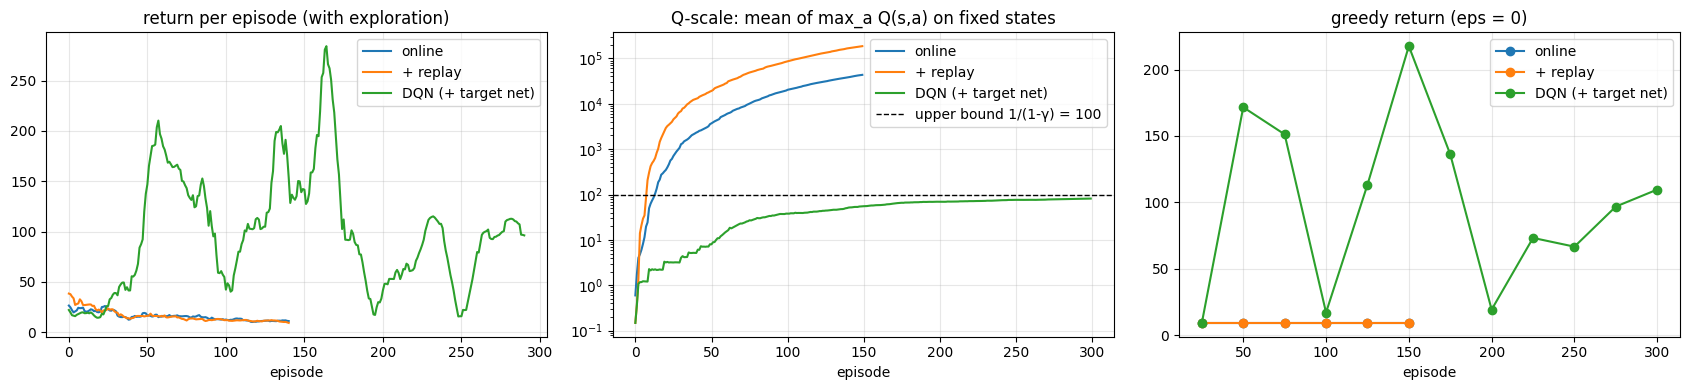

In [19]:
def smooth(x, w=10):
    return np.convolve(x, np.ones(w) / w, mode='valid')

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for name, log in [('online', log_online), ('+ replay', log_replay), ('DQN (+ target net)', log_dqn)]:
    ax[0].plot(smooth(log['returns']), label=name)
    ax[1].semilogy(np.maximum(np.abs(log['q_scale']), 1e-1), label=name)
    ep, g = zip(*log['evals']) if log['evals'] else ([], [])
    ax[2].plot(ep, g, 'o-', label=name)
ax[1].axhline(100, color='k', ls='--', lw=1, label='upper bound 1/(1-γ) = 100')
ax[0].set_title('return per episode (with exploration)'); ax[1].set_title('Q-scale: mean of max_a Q(s,a) on fixed states')
ax[2].set_title('greedy return (eps = 0)')
for a in ax:
    a.set_xlabel('episode'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Think.** Is the greedy return monotone in the number of episodes? What do we do about it?

<details><summary>Answer</summary>

No. DQN on CartPole often reaches 500 and then drops again, and recovers later. Once the agent balances well, the buffer fills with states near the upright position and the network forgets how to recover from the rest ("catastrophic forgetting", the problem of B.1 in a milder form). In practice we evaluate the greedy policy periodically (here every 25 episodes) and keep the best network.

</details>

In [20]:
def play(q, seed=0, max_steps=500, every=2, title=''):
    rng = np.random.default_rng(seed)
    s, _ = env.reset(seed=seed); frames, G, done = [env.render()], 0, False
    while not done and G < max_steps:
        s, r, term, trunc, _ = env.step(act(q, s, 0.0, rng)); done = term or trunc; G += r
        if int(G) % every == 0:
            frames.append(env.render())
    fig, ax = plt.subplots(figsize=(5, 3.3))
    im = ax.imshow(frames[0]); ax.axis('off'); ax.set_title(f'{title}: {G:.0f} steps')
    anim = animation.FuncAnimation(fig, lambda i: [im.set_array(frames[i])], frames=len(frames), interval=40)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode='once'))

display(play(log_dqn['best'], title='DQN, best network'))
display(play(log_online['final'], title='online Q-learning, final network'))

## Part D. Atari: pixels, frames, and the Markov property

### D.1 The setup

The Arcade Learning Environment: 2600 Atari games, screens of $210\times160$ RGB at 60 frames per second, up to 18 actions. DQN (Mnih et al., 2015) used **the same network and the same hyperparameters for 49 games**, learning from pixels and the score only, and reached human level on many of them.

**The preprocessing pipeline**, step by step:

| step | what | why |
|---|---|---|
| frame skip $k=4$ | the agent chooses an action every 4th frame; the action is repeated, rewards are summed | 4× less computation, 15 decisions per second is enough, and each decision has a visible effect |
| max over 2 frames | each processed frame is the pixel-wise max of the last two raw frames | **flicker**: the console could draw only a few sprites per frame, so many games draw some objects only on even frames and others only on odd frames |
| grayscale, $84\times84$ | resize and drop color | 28,224 inputs instead of 100,800; color rarely matters |
| **stack $m=4$** | the state is the last 4 processed frames, a $4\times84\times84$ tensor | **one frame is not a Markov state** (D.2) |
| reward clipping | rewards clipped to $[-1,1]$ | the same learning rate works for games with scores of 1 and of 1000 (but "a little" and "a lot" now look the same) |
| (training only) | a lost life counts as terminal; random number of no-ops at the start | faster credit assignment; varied starting states |

### D.2 Why one frame is not enough

Our methods assume the **Markov property**: the next state and reward depend only on the current state and action. The true state of an Atari game is the console's memory (128 bytes of RAM): positions **and velocities** of all objects, timers, counters. The agent sees only the screen, an **observation** of that state: the problem is a **partially observable** MDP.

A single frame shows where the ball is, not where it is going. Two different states (ball moving left, ball moving right) produce the **same** frame, so any function of one frame must give them the same Q-values, and the agent cannot act optimally in both.

With a stack of frames, differences between frames give the velocity, three frames give the acceleration: the stack **approximately** restores the Markov property for things that move.

last frames equal:           True
stacks of the last 2 equal:  False


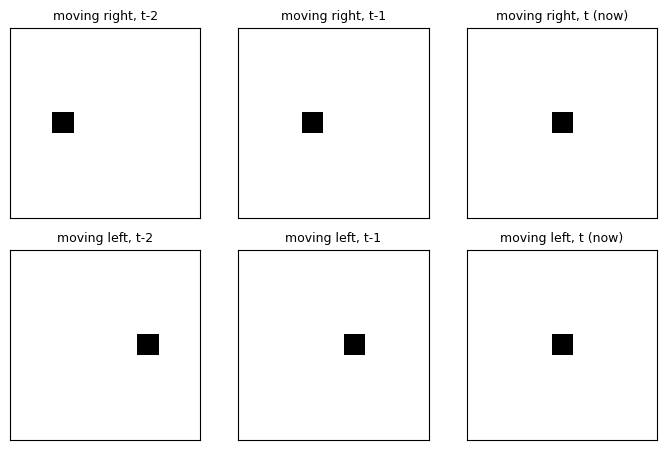

In [21]:
def frame(ball, size=9):
    img = np.zeros((size, size)); img[ball] = 1.0; return img

# two different states that look the same: the ball at (4, 4) moving right, or moving left
right = [frame((4, 2)), frame((4, 3)), frame((4, 4))]
left = [frame((4, 6)), frame((4, 5)), frame((4, 4))]
print('last frames equal:          ', np.array_equal(right[-1], left[-1]))
print('stacks of the last 2 equal: ', np.array_equal(np.stack(right[-2:]), np.stack(left[-2:])))

fig, ax = plt.subplots(2, 3, figsize=(7, 4.6))
for row, (seq, name) in enumerate([(right, 'moving right'), (left, 'moving left')]):
    for t in range(3):
        ax[row, t].imshow(seq[t], cmap='gray_r', vmin=0, vmax=1)
        ax[row, t].set_xticks([]); ax[row, t].set_yticks([])
        ax[row, t].set_title(f'{name}, t-{2 - t}' if t < 2 else f'{name}, t (now)', fontsize=9)
plt.tight_layout(); plt.show()

### D.3 The problem with a fixed number of frames

A stack of the last $m$ frames is a **truncated history**: the agent treats the problem as if the last $m$ observations were the state. That is fine for velocities, but a fixed window has several problems.

1. **A fixed memory horizon.** With $m=4$ and frame skip 4, the agent remembers 16 raw frames, about **0.27 seconds**. Anything that is not visible now and happened earlier is gone: an object that left the screen or is hidden behind another, a signal shown once (which door opens, which way an enemy went), how many times something happened. For such games the stacked state is still not Markov, and **no amount of training** fixes it: the information is not in the input.
2. **The window size is a hand-made choice.** $m=4$ was chosen for Atari. Too small and velocities are ambiguous, too large and the input and the replay memory grow, and it is still finite: the right $m$ depends on the game.
3. **Flicker and frame skip interact.** If an object is drawn only on odd frames and the agent looks at every 4th frame, it may be invisible in **all** frames of the stack. This is why the max over two consecutive raw frames is needed.
4. **Episode boundaries.** At the start of an episode there are fewer than $m$ frames; a stack that crosses a boundary would mix the end of one game with the start of the next. Pad with zeros (or repeat the first frame), and make the replay memory respect boundaries.
5. **Memory in the replay buffer.** A transition $(s,a,r,s',d)$ with stacked $s$ and $s'$ stores 8 frames, but consecutive stacks share 3 of their 4 frames. Store each frame **once** and rebuild the stacks from indices.

A toy example of problem 1: a light flashes at time 0 on the left or the right; at time $D$ the agent must go to that side. A policy that sees the last $m$ frames succeeds only if the flash is still in its window, $m>D$; otherwise it can only guess.

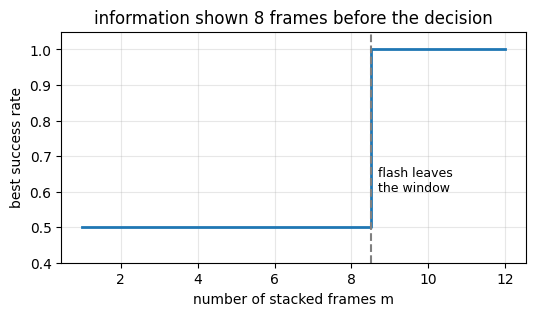

storing stacked s and s' for every transition:  56.4 GB
storing every frame once, stacks rebuilt from indices:   7.1 GB


In [22]:
D_delay = 8                                         # the decision is made 8 frames after the flash
ms = np.arange(1, 13)
success = np.where(ms > D_delay, 1.0, 0.5)          # in the window: always right; outside: a coin flip
plt.figure(figsize=(6, 3))
plt.step(ms, success, where='mid', lw=2)
plt.axvline(D_delay + 0.5, ls='--', c='gray'); plt.text(D_delay + 0.7, 0.6, 'flash leaves\nthe window', fontsize=9)
plt.xlabel('number of stacked frames m'); plt.ylabel('best success rate'); plt.ylim(0.4, 1.05)
plt.title(f'information shown {D_delay} frames before the decision'); plt.grid(alpha=.3); plt.show()

# problem 5: replay memory for 1M Atari transitions, one byte per pixel
N, px, m = 1_000_000, 84 * 84, 4
print(f'storing stacked s and s\' for every transition: {N * 2 * m * px / 1e9:5.1f} GB')
print(f'storing every frame once, stacks rebuilt from indices: {N * px / 1e9:5.1f} GB')

### D.4 Beyond a fixed window: learned memory

The principled fix is to let the network **learn what to remember**:
* **DRQN** (Hausknecht and Stone, 2015) feeds one frame per step into a recurrent network (an LSTM), whose hidden state summarizes the whole history. On "flickering" Pong, where each frame is blanked out with probability ½, it coped much better with missing frames than a frame-stacking DQN.
* **R2D2** (Kapturowski et al., 2019) combines recurrent networks with replay. Replay now stores **sequences**, and the hidden state stored with them is stale (computed by an old network), so each sampled sequence starts with a "burn-in" segment that recomputes it.
* Transformers attend over a long window of past observations instead of compressing it into one vector.

Recurrent networks are the next topic of the course; this is one of the reasons we need them.

### D.5 The Atari network

A convolutional network maps the $4\times84\times84$ stack to one Q-value per action. The output size of a convolution is $\lfloor(W-K+2P)/S\rfloor+1$:

In [23]:
atari_q = nn.Sequential(
    nn.Conv2d(4, 32, kernel_size=8, stride=4), nn.ReLU(),
    nn.Conv2d(32, 64, kernel_size=4, stride=2), nn.ReLU(),
    nn.Conv2d(64, 64, kernel_size=3, stride=1), nn.ReLU(),
    nn.Flatten(),
    nn.Linear(64 * 7 * 7, 512), nn.ReLU(),
    nn.Linear(512, 18))                          # 18 = all Atari actions

x = torch.zeros(1, 4, 84, 84)
for layer in atari_q:
    x = layer(x)
    n = sum(p.numel() for p in layer.parameters())
    print(f'{layer.__class__.__name__:8s} -> output {tuple(x.shape)}   parameters {n:,}')
print(f'total: {sum(p.numel() for p in atari_q.parameters()):,} parameters')
print(f'one fully connected layer of 512 units on the raw input alone: {4 * 84 * 84 * 512 + 512:,}')

Conv2d   -> output (1, 32, 20, 20)   parameters 8,224
ReLU     -> output (1, 32, 20, 20)   parameters 0
Conv2d   -> output (1, 64, 9, 9)   parameters 32,832
ReLU     -> output (1, 64, 9, 9)   parameters 0
Conv2d   -> output (1, 64, 7, 7)   parameters 36,928
ReLU     -> output (1, 64, 7, 7)   parameters 0
Flatten  -> output (1, 3136)   parameters 0
Linear   -> output (1, 512)   parameters 1,606,144
ReLU     -> output (1, 512)   parameters 0
Linear   -> output (1, 18)   parameters 9,234
total: 1,693,362 parameters
one fully connected layer of 512 units on the raw input alone: 14,451,200


**Think.** The frames enter the first convolution as 4 **channels**. Does the number of stacked frames $m$ change the number of parameters much? What is the network's view of time?

<details><summary>Answer</summary>

Only the first layer depends on $m$: it has $32\cdot m\cdot8\cdot8+32$ parameters, 8,224 for $m=4$, a small part of the 1.7 M (most sit in the fully connected layer). The network sees time only as extra channels: frame $t-3$ and frame $t$ are treated like the red and blue channels of a color image, with no notion of order beyond the learned weights, and nothing outside the window.

</details>

## Part E. The cross-entropy method: search directly in policy space

### E.1 A completely different idea

DQN learns values and acts greedily on them. It needs the Bellman equation, hence a Markov state, and makes careful use of every transition. The **cross-entropy method** (CEM) forgets all of that:
> sample many policies, play them, keep the best few, move the sampling distribution towards them, and repeat.

It uses **one number per episode**, its return. No values, no gradients, no Markov assumption.

### E.2 The algorithm

Take a parametric policy, here a **linear** policy for CartPole: push right if $\theta_{1:4}^\top s+\theta_5>0$, else left. Keep a Gaussian $\mathcal N(\mu,\operatorname{diag}\sigma^2)$ over $\theta\in\mathbb R^5$:
1. **Sample** $\theta_1,\dots,\theta_N\sim\mathcal N(\mu,\sigma^2)$ ($N=50$).
2. **Evaluate**: play an episode with each, returns $R_1,\dots,R_N$.
3. **Select the elites**: the top fraction $\rho$ (20%) by return.
4. **Refit**: $\mu\leftarrow$ mean of the elites, $\sigma^2\leftarrow$ their variance (+ a small extra noise, E.4).

### E.3 Why "cross-entropy"

The name comes from Rubinstein (1997), who developed the method to estimate probabilities of rare events. Let $f(\theta;v)$ be the current sampling density and $\gamma$ the elite threshold. The ideal next sampling density keeps only the good samples, $g^*(\theta)\propto\mathbf 1\{J(\theta)\ge\gamma\}f(\theta;v)$. We choose the member of our family closest to it in KL divergence, which is the cross-entropy up to a constant:
$$
\min_{v'}\mathrm{KL}(g^*\,\|\,f_{v'})\iff\max_{v'}\ \mathbb E_{v}\bigl[\mathbf 1\{J(\theta)\ge\gamma\}\log f(\theta;v')\bigr]\approx\max_{v'}\sum_{i\in\text{elite}}\log f(\theta_i;v').
$$
That is **maximum likelihood on the elite samples**; for a Gaussian, the elite mean and variance of step 4. The threshold $\gamma$ rises from one iteration to the next, so "rare" good events become common.

In [24]:
def linear_policy(theta, s):
    return int(s @ theta[:4] + theta[4] > 0)

def run_episode(theta, seed, max_steps=500):
    s, _ = env.reset(seed=int(seed)); G, done = 0.0, False
    while not done and G < max_steps:
        s, r, term, trunc, _ = env.step(linear_policy(theta, s)); done = term or trunc; G += r
    return G

def cem(n_iter=12, N=50, elite_frac=0.2, sigma0=1.0, extra_noise=0.25, seed=0, verbose=True):
    rng = np.random.default_rng(seed)
    mu, sigma = np.zeros(5), np.full(5, sigma0)
    n_elite, hist, env_steps = int(N * elite_frac), [], 0
    for it in range(n_iter):
        thetas = mu + sigma * rng.standard_normal((N, 5))                   # 1. sample
        R = np.array([run_episode(th, rng.integers(1 << 31)) for th in thetas])   # 2. evaluate
        env_steps += int(R.sum())
        elite = thetas[np.argsort(R)[-n_elite:]]                             # 3. the best 20%
        threshold = np.sort(R)[-n_elite]
        mu = elite.mean(axis=0)                                              # 4. refit
        sigma = elite.std(axis=0) + extra_noise * max(0.0, 1 - it / 5)       #    + decreasing extra noise
        hist.append((R.mean(), threshold, R.max(), sigma.mean(), env_steps))
        if verbose:
            print(f'iter {it + 1:2d}  mean return {R.mean():6.1f}  elite threshold {threshold:5.0f}  '
                  f'best {R.max():4.0f}  mean sigma {sigma.mean():.3f}  env steps {env_steps:7,}')
    return mu, hist

t0 = time.time()
mu_cem, hist = cem()
test = [run_episode(mu_cem, 1000 + k) for k in range(20)]
print(f'\nthe mean policy mu: {np.round(mu_cem, 2)};  return over 20 test episodes: {np.mean(test):.0f}  ({time.time() - t0:.0f} s)')

iter  1  mean return   13.5  elite threshold    14  best   94  mean sigma 1.028  env steps     673
iter  2  mean return   25.8  elite threshold    37  best   85  mean sigma 0.871  env steps   1,965
iter  3  mean return   64.7  elite threshold    84  best  500  mean sigma 0.933  env steps   5,201
iter  4  mean return   63.6  elite threshold    85  best  242  mean sigma 0.809  env steps   8,382
iter  5  mean return   96.2  elite threshold   114  best  500  mean sigma 0.637  env steps  13,190
iter  6  mean return  117.7  elite threshold   117  best  500  mean sigma 0.636  env steps  19,073
iter  7  mean return  160.8  elite threshold   246  best  500  mean sigma 0.566  env steps  27,115
iter  8  mean return  211.1  elite threshold   396  best  500  mean sigma 0.431  env steps  37,671
iter  9  mean return  351.4  elite threshold   500  best  500  mean sigma 0.385  env steps  55,242
iter 10  mean return  452.0  elite threshold   500  best  500  mean sigma 0.324  env steps  77,843
iter 11  m

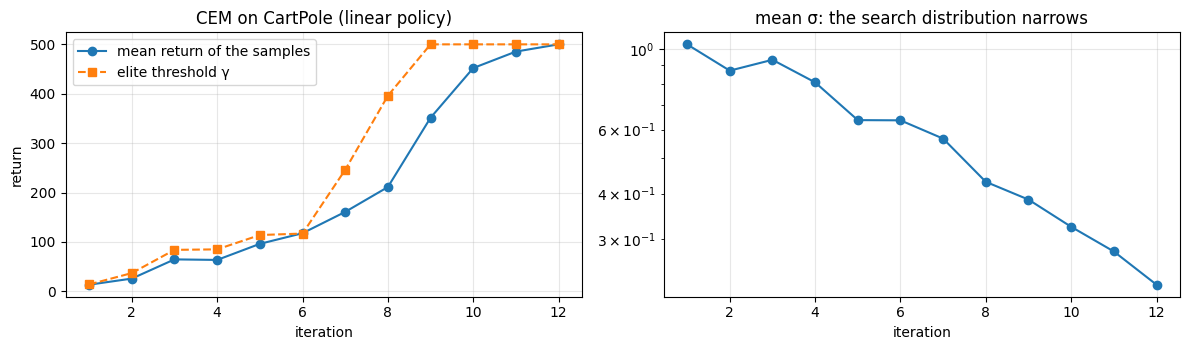

environment steps used: CEM 127,111   DQN (300 episodes) 28,990


In [25]:
h = np.array(hist)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(range(1, len(h) + 1), h[:, 0], 'o-', label='mean return of the samples')
ax[0].plot(range(1, len(h) + 1), h[:, 1], 's--', label='elite threshold γ')
ax[0].set(xlabel='iteration', ylabel='return', title='CEM on CartPole (linear policy)'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].semilogy(range(1, len(h) + 1), h[:, 3], 'o-')
ax[1].set(xlabel='iteration', title='mean σ: the search distribution narrows'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

steps_dqn = sum(log_dqn['returns'])
print(f'environment steps used: CEM {int(h[-1, 4]):,}   DQN (300 episodes) {int(steps_dqn):,}')

### E.4 The whole picture on the toy MDP: CEM and policy gradient on the exact objective

On CartPole we cannot see the objective. On the toy MDP from Part A.2 we can compute it **exactly**. Take a policy with two parameters,
$$
\pi(\text{go}\mid A)=\sigma(\theta_A),\qquad \pi(\text{cash}\mid B)=\sigma(\theta_B),\qquad \sigma(x)=\frac1{1+e^{-x}} .
$$
For a fixed $\theta$ the policy turns the MDP into a Markov reward process, and the evaluation lecture gave its values exactly: $V^\pi=(I-\gamma P^\pi)^{-1}r^\pi$. The objective is the value of the start state,
$$
J(\theta_A,\theta_B)=V^{\pi_\theta}(A),
$$
a function of two numbers that we can draw as a map.

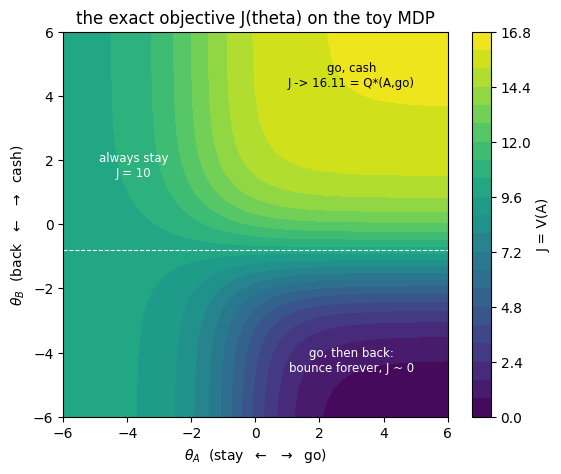

J at the corners: stay 10.00, go+back 0.02, go+cash 16.11, start point (-2,-2): 8.90


In [26]:
from matplotlib.patches import Ellipse

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def J_exact(tA, tB):
    """V(A) of the policy (pi(go|A), pi(cash|B)) = (sigmoid(tA), sigmoid(tB)), by solving the Bellman equation."""
    pA, pB = sigmoid(tA), sigmoid(tB)
    P_pi = np.array([[(1 - pA) * 1.0 + pA * 0.2, pA * 0.8],      # from A: stay -> A, go -> A (0.2) or B (0.8)
                     [pB * 0.3 + (1 - pB) * 1.0, 0.0]])          # from B: cash -> A (0.3) or G, back -> A
    r_pi = np.array([(1 - pA) * 1.0, pB * 0.7 * 20.0])
    return np.linalg.solve(np.eye(2) - gamma_toy * P_pi, r_pi)[0]

grid = np.linspace(-6, 6, 121)
JJ = np.array([[J_exact(a, b) for a in grid] for b in grid])

def draw_landscape(ax):
    cs = ax.contourf(grid, grid, JJ, levels=24, cmap='viridis')
    ax.contour(grid, grid, JJ, levels=[10.0], colors='w', linewidths=0.8, linestyles='--')
    ax.set_xlabel(r'$\theta_A$  (stay  $\leftarrow$  $\rightarrow$  go)')
    ax.set_ylabel(r'$\theta_B$  (back  $\leftarrow$  $\rightarrow$  cash)')
    return cs

fig, ax = plt.subplots(figsize=(6.2, 5))
plt.colorbar(draw_landscape(ax), label='J = V(A)')
for (a, b, txt, c) in [(-3.8, 1.5, 'always stay\nJ = 10', 'w'), (3.0, -4.6, 'go, then back:\nbounce forever, J ~ 0', 'w'),
                       (3.0, 4.3, 'go, cash\nJ -> 16.11 = Q*(A,go)', 'k')]:
    ax.text(a, b, txt, color=c, ha='center', fontsize=8.5)
ax.set_title('the exact objective J(theta) on the toy MDP'); plt.show()
print(f'J at the corners: stay {J_exact(-8, 0):.2f}, go+back {J_exact(8, -8):.2f}, go+cash {J_exact(8, 8):.2f}, start point (-2,-2): {J_exact(-2, -2):.2f}')

Three regions: a **plateau** on the left (always stay: $+1$ forever, $J=1/(1-\gamma)=10$), a **trap** at the bottom right (go to $B$, then always back: bouncing between $A$ and $B$ forever with no reward), and the **optimum** at the top right (go, cash: $J\to16.11=Q^*(A,\text{go})$). The dashed line is $J=10$: anything below it is worse than staying.

**Tabular CEM first: the counting update, printed.** The policy is the table of two probabilities. Play 50 episodes with it, keep the 10 with the highest discounted return, and count what the elites did in each state.

In [27]:
def toy_episode(pA, pB, rng, T=200):
    """One episode from A with pi(go|A)=pA, pi(cash|B)=pB. Returns (discounted return, list of (s, a))."""
    s, G, disc, traj = 'A', 0.0, 1.0, []
    for _ in range(T):
        a = ('go' if rng.random() < pA else 'stay') if s == 'A' else ('cash' if rng.random() < pB else 'back')
        s2, r = toy_step(s, a, rng)
        traj.append((s, a)); G += disc * r; disc *= gamma_toy; s = s2
        if s in TERMINAL:
            break
    return G, traj

rng_t = np.random.default_rng(0)
pi_tab = {'A': 0.5, 'B': 0.5}                       # pi(go|A), pi(cash|B)
for it in range(4):
    eps = [toy_episode(pi_tab['A'], pi_tab['B'], rng_t) for _ in range(50)]
    G = np.array([e[0] for e in eps])
    elite = [eps[i][1] for i in np.argsort(G)[-10:]]
    pairs = [sa for tr in elite for sa in tr]
    n_go = sum(sa == ('A', 'go') for sa in pairs); n_A = sum(s == 'A' for s, _ in pairs)
    n_cash = sum(sa == ('B', 'cash') for sa in pairs); n_B = sum(s == 'B' for s, _ in pairs)
    new = {'A': n_go / n_A, 'B': n_cash / n_B if n_B else pi_tab['B']}
    print(f'iteration {it + 1}: mean return {G.mean():5.2f}, elite threshold {np.sort(G)[-10]:5.2f}')
    print(f'   elites took go in A {n_go} times out of {n_A} visits, cash in B {n_cash} out of {n_B}')
    pi_tab = {s: 0.5 * new[s] + 0.5 * pi_tab[s] for s in pi_tab}          # smoothing, lambda = 0.5
    print(f'   new policy: pi(go|A) = {pi_tab["A"]:.2f},  pi(cash|B) = {pi_tab["B"]:.2f}')

iteration 1: mean return 10.96, elite threshold 16.48
   elites took go in A 10 times out of 22 visits, cash in B 10 out of 10
   new policy: pi(go|A) = 0.48,  pi(cash|B) = 0.75
iteration 2: mean return 13.27, elite threshold 18.00
   elites took go in A 10 times out of 10 visits, cash in B 10 out of 10
   new policy: pi(go|A) = 0.74,  pi(cash|B) = 0.88
iteration 3: mean return 14.74, elite threshold 18.00
   elites took go in A 10 times out of 10 visits, cash in B 10 out of 10
   new policy: pi(go|A) = 0.87,  pi(cash|B) = 0.94
iteration 4: mean return 16.12, elite threshold 18.00
   elites took go in A 10 times out of 10 visits, cash in B 10 out of 10
   new policy: pi(go|A) = 0.93,  pi(cash|B) = 0.97


**Now in parameter space: CEM versus REINFORCE on the map.** Both start at $\theta=(-2,-2)$, mostly *stay* and *back*, $J=8.90$.
* **CEM** samples 30 parameter vectors from a Gaussian, scores each by the average discounted return of 5 episodes, and refits the Gaussian to the best 6.
* **REINFORCE** plays 10 episodes with the current $\theta$ and steps along the estimated gradient
$$
\widehat{\nabla J}=\frac1n\sum_{i}\bigl(G^i-b\bigr)\sum_t\nabla_\theta\log\pi_\theta(a^i_t\mid s^i_t),\qquad b=\text{mean of the }G^i,
$$
with $\nabla_{\theta_A}\log\pi(\text{go}\mid A)=1-\sigma(\theta_A)$ and $\nabla_{\theta_A}\log\pi(\text{stay}\mid A)=-\sigma(\theta_A)$ (and the same for $B$).

First check that this estimate really is the gradient of $J$: compare it, with many episodes, against finite differences of `J_exact`.

In [28]:
def grad_log_pi(s, a, th):
    if s == 'A':
        return np.array([1 - sigmoid(th[0]) if a == 'go' else -sigmoid(th[0]), 0.0])
    return np.array([0.0, 1 - sigmoid(th[1]) if a == 'cash' else -sigmoid(th[1])])

def reinforce_estimate(th, n, rng):
    eps = [toy_episode(sigmoid(th[0]), sigmoid(th[1]), rng) for _ in range(n)]
    G = np.array([e[0] for e in eps]); b = G.mean()
    return np.mean([(Gi - b) * sum(grad_log_pi(s, a, th) for s, a in tr) for Gi, (_, tr) in zip(G, eps)], axis=0)

th0, h = np.array([-1.0, 0.5]), 1e-4
exact = np.array([(J_exact(th0[0] + h, th0[1]) - J_exact(th0[0] - h, th0[1])) / (2 * h),
                  (J_exact(th0[0], th0[1] + h) - J_exact(th0[0], th0[1] - h)) / (2 * h)])
print('at theta =', th0)
print('   exact gradient (finite differences of J):', exact.round(3))
print('   REINFORCE estimate, 20,000 episodes     :', reinforce_estimate(th0, 20000, np.random.default_rng(0)).round(3))
print('   REINFORCE estimate, 10 episodes (x3)    :', [reinforce_estimate(th0, 10, np.random.default_rng(k)).round(2) for k in range(3)])

at theta = [-1.   0.5]
   exact gradient (finite differences of J): [0.892 1.444]
   REINFORCE estimate, 20,000 episodes     : [0.918 1.429]
   REINFORCE estimate, 10 episodes (x3)    : [array([1.88, 1.05]), array([-0.51,  1.46]), array([1.72, 0.29])]


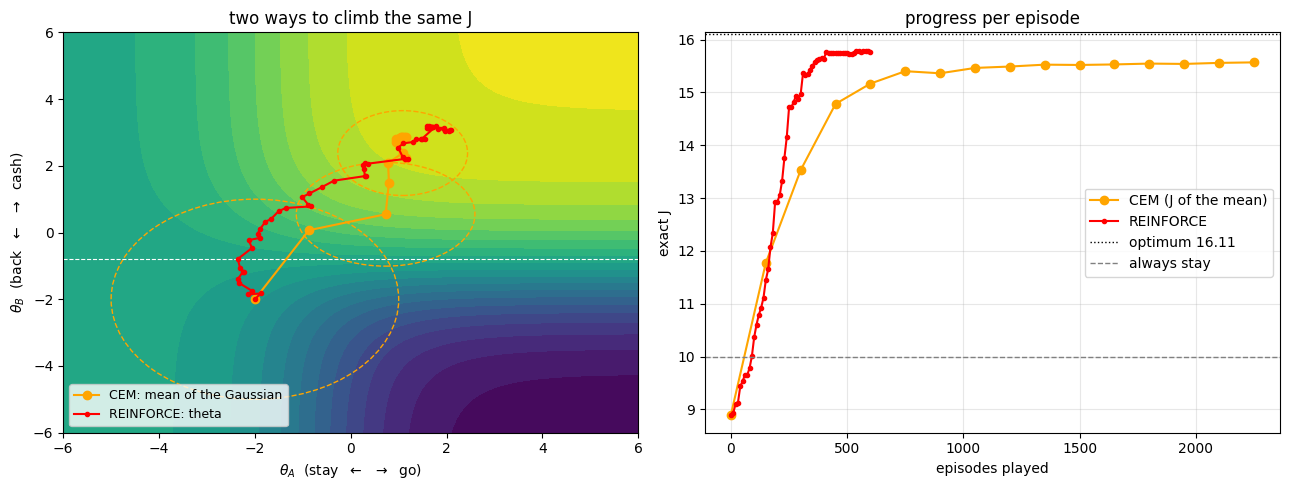

CEM: J = 15.57 after 2250 episodes;  REINFORCE: J = 15.77 after 600 episodes


In [29]:
def cem_toy(mu0=(-2.0, -2.0), N=30, n_elite=6, n_iter=15, n_eps=5, seed=0):
    rng = np.random.default_rng(seed)
    mu, sd = np.array(mu0), np.array([1.5, 1.5])
    hist = [(mu.copy(), sd.copy(), 0)]
    for k in range(n_iter):
        TH = mu + sd * rng.standard_normal((N, 2))
        R = np.array([np.mean([toy_episode(sigmoid(t[0]), sigmoid(t[1]), rng)[0] for _ in range(n_eps)]) for t in TH])
        el = TH[np.argsort(R)[-n_elite:]]
        mu, sd = el.mean(0), el.std(0) + 0.3 * max(0.0, 1 - k / 6)
        hist.append((mu.copy(), sd.copy(), (k + 1) * N * n_eps))
    return hist

def reinforce_toy(th0=(-2.0, -2.0), n_iter=60, n=10, lr=0.2, seed=0):
    rng = np.random.default_rng(seed)
    th = np.array(th0); path = [(th.copy(), 0)]
    for k in range(n_iter):
        th = th + lr * reinforce_estimate(th, n, rng)
        path.append((th.copy(), (k + 1) * n))
    return path

cem_h, pg_h = cem_toy(), reinforce_toy()
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
draw_landscape(ax[0])
for k in (0, 2, 5, 15):
    m, s, _ = cem_h[k]
    ax[0].add_patch(Ellipse(m, 4 * s[0], 4 * s[1], fill=False, color='orange', ls='--', lw=1))
ax[0].plot(*np.array([m for m, _, _ in cem_h]).T, 'o-', color='orange', label='CEM: mean of the Gaussian')
ax[0].plot(*np.array([t for t, _ in pg_h]).T, '.-', color='red', label='REINFORCE: theta')
ax[0].legend(loc='lower left', fontsize=9); ax[0].set_title('two ways to climb the same J')
ax[1].plot([e for _, _, e in cem_h], [J_exact(*m) for m, _, _ in cem_h], 'o-', color='orange', label='CEM (J of the mean)')
ax[1].plot([e for _, e in pg_h], [J_exact(*t) for t, _ in pg_h], '.-', color='red', label='REINFORCE')
ax[1].axhline(16.11, color='k', ls=':', lw=1, label='optimum 16.11'); ax[1].axhline(10, color='gray', ls='--', lw=1, label='always stay')
ax[1].set(xlabel='episodes played', ylabel='exact J', title='progress per episode'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f'CEM: J = {J_exact(*cem_h[-1][0]):.2f} after {cem_h[-1][2]} episodes;  REINFORCE: J = {J_exact(*pg_h[-1][0]):.2f} after {pg_h[-1][1]} episodes')

**What to see.**
* Both climb the same exact $J$ to the top-right corner, (go, cash). CEM moves a whole **cloud** (the dashed ellipses) and jumps; REINFORCE follows a single **noisy path** of small gradient steps.
* REINFORCE's 10-episode gradient estimates are noisy (the three estimates in the check differ), but on average they are the true gradient. That is what "unbiased" means.
* Per episode, REINFORCE is far more economical here: every episode contributes to the gradient, while CEM scores 30 × 5 episodes per iteration and keeps a fifth of the samples.
* Neither reaches 16.11 exactly: that needs $\theta\to\infty$ (a deterministic policy), and both slow down as the policy becomes nearly deterministic, because $\nabla\log\pi\to0$ for the action almost always taken.

**Think.** Rank the episodes by the **undiscounted** total reward instead (with episodes cut at 200 steps). Which corner would CEM go to now, and why?

<details><summary>Answer</summary>

The "always stay" corner: staying collects $+1$ per step, i.e. up to 200 per episode, while reaching $G$ pays 20 once. The method optimizes exactly the score you rank by; the discounted return $\sum_t\gamma^tr_t$ is what makes cashing in worth more than staying ($16.11$ versus $10$).

</details>

### E.5 Practical points

* **Variance collapse.** $\sigma$ can shrink too fast and freeze the search on a mediocre policy. Adding a small, decreasing extra noise to $\sigma$ fixes it (Szita and Lőrincz, 2006, who used CEM to learn Tetris far better than earlier RL methods).
* **Noisy returns.** With one episode per sample, some elites are just lucky. Average a few episodes per sample in noisy problems.
* **Scale.** CEM works very well with a few to a few hundred parameters, and it is trivially parallel. With millions of parameters, sampling in parameter space becomes hopeless; its refined relatives are evolution strategies and CMA-ES.
* **Data.** A whole episode becomes **one number**, and 80% of the episodes are thrown away. In our run CEM used about three times as many environment steps as DQN's 300 episodes, but each step is far cheaper (no network, no gradient), it took seconds, and it ended with a policy that balanced for 500 steps in every test episode. CartPole is easy for CEM: a linear policy suffices and the search space is only $\mathbb R^5$.

### E.6 CEM with a policy network, and the road to policy gradients

A second form of CEM (common in teaching) works in **episode space**: play $N$ episodes with a stochastic policy network $\pi_\theta(a\mid s)$, keep the top-$\rho$ episodes, and train the network by **cross-entropy classification** on the $(s,a)$ pairs of the elite episodes, i.e. imitate your own best behavior:
$$
\theta\leftarrow\theta+\alpha\sum_{\text{episodes }i}\underbrace{\mathbf 1\{R_i\ge\gamma\}}_{\text{weight }0\text{ or }1}\ \sum_t\nabla_\theta\log\pi_\theta(a_t^i\mid s_t^i).
$$
**REINFORCE** (Williams, 1992) replaces the crude 0/1 weight by the return itself, minus a baseline $b$:
$$
\theta\leftarrow\theta+\alpha\sum_i\bigl(R_i-b\bigr)\sum_t\nabla_\theta\log\pi_\theta(a_t^i\mid s_t^i),
$$
which is an unbiased estimate of $\nabla_\theta\,\mathbb E[R]$ (the policy gradient theorem) and uses **all** the episodes. Replacing $R_i-b$ by a learned value estimate gives **actor–critic**, with TD learning back inside. The same update, with a learned reward model as $R$, is how LLMs are fine-tuned from human feedback (RLHF): we will meet it again at the end of the course.